In [1]:
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics import calinski_harabasz_score

import warnings

warnings.filterwarnings(
    "ignore",
    message="KMeans is known to have a memory leak on Windows"
)

sns.set_theme()

** Carrgeando dados **

In [2]:
df = pd.read_csv('C:\\Users\\diego\\OneDrive\\Documentos_OneDrive\\Python-Machine-Learning-Clustering\\dados\\mallcustomers.csv')

In [3]:
df.head(2)

,CustomerID,Gender,Age,Income,SpendingScore
0,1,Male,19,15000,39
1,2,Male,21,15000,81


** Explorando o dataset **

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   CustomerID     200 non-null    int64
 1   Gender         200 non-null    str  
 2   Age            200 non-null    int64
 3   Income         200 non-null    int64
 4   SpendingScore  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [5]:
df.describe(include='all').round(2)

,CustomerID,Gender,Age,Income,SpendingScore
count,200.00,200,200.00,200.00,200.00
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.50,NaN,38.85,60560.00,50.20
std,57.88,NaN,13.97,26264.72,25.82
min,1.00,NaN,18.00,15000.00,1.00
25%,50.75,NaN,28.75,41500.00,34.75
50%,100.50,NaN,36.00,61500.00,50.00
75%,150.25,NaN,49.00,78000.00,73.00


** Visualização Gráfica **

C:\Users\diego\AppData\Local\Temp\ipykernel_31500\2210490564.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,


<Axes: xlabel='Gender', ylabel='Income'>

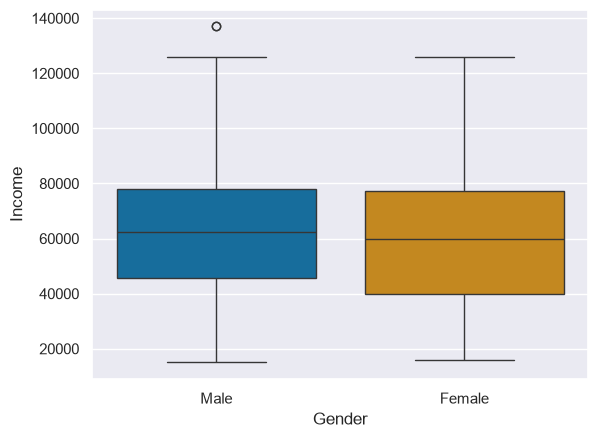

In [6]:
sns.boxplot(data=df, 
            x='Gender', 
            y='Income', 
            palette='colorblind')

C:\Users\diego\AppData\Local\Temp\ipykernel_31500\2439859248.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(data=df,


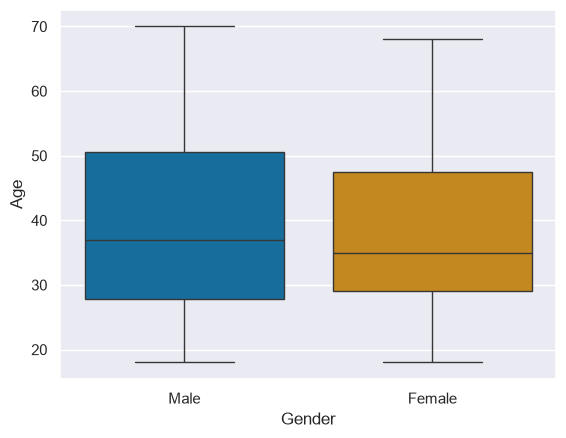

In [7]:
ax = sns.boxplot(data=df, 
            x='Gender', 
            y='Age', 
            palette='colorblind')

In [8]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Income', 'SpendingScore'], dtype='str')

C:\Users\diego\AppData\Local\Temp\ipykernel_31500\2886847844.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,


<Axes: xlabel='Gender', ylabel='SpendingScore'>

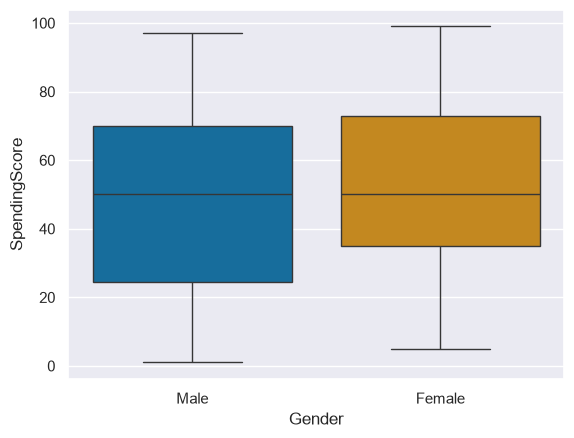

In [9]:
sns.boxplot(data=df, 
            x='Gender', 
            y='SpendingScore', 
            palette='colorblind')

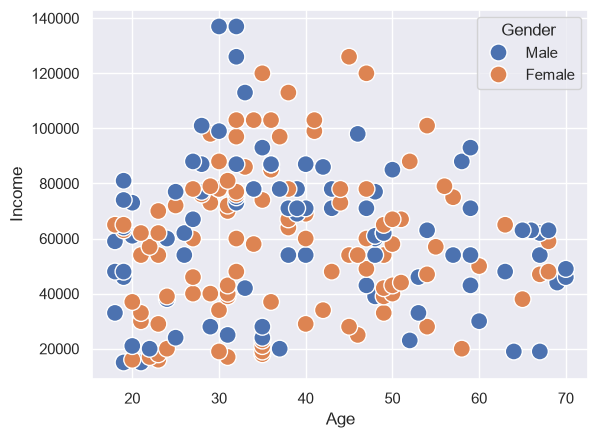

In [10]:
ax = sns.scatterplot(
                data=df,
                 x='Age',
                 y='Income',
                 hue='Gender',
                 s=150)    

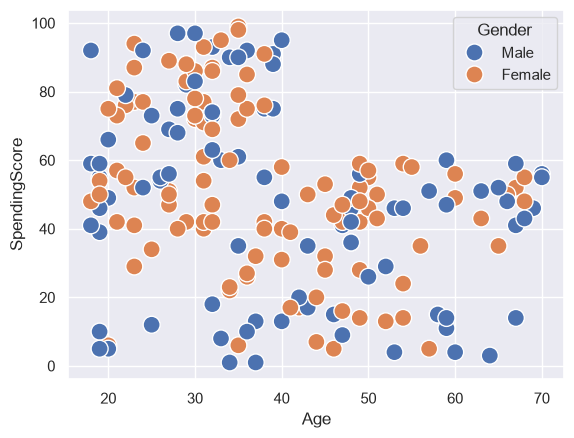

In [11]:
ax = sns.scatterplot(
                data=df,
                 x='Age',
                 y='SpendingScore',
                 hue='Gender',
                 s=150)    

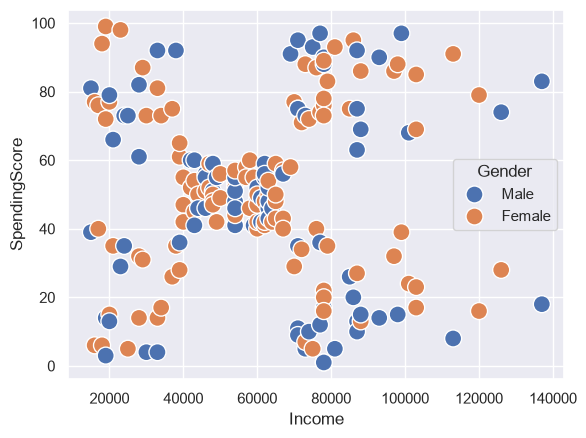

In [12]:
# Para ver a relação entre a renda e o score de gastos, podemos observar algum agrupamento possivel.
ax = sns.scatterplot(
                data=df,
                 x='Income',
                 y='SpendingScore',
                 hue='Gender',
                 s=150)    

** Preparar os dados **

In [13]:
df[[ 'Income' , 'SpendingScore']].describe().round(2)

,Income,SpendingScore
count,200.00,200.00
mean,60560.00,50.20
std,26264.72,25.82
min,15000.00,1.00
25%,41500.00,34.75
50%,61500.00,50.00
75%,78000.00,73.00
max,137000.00,99.00


O desvio-padrão da renda (26264.72) embrora o score de gastos é de (25.82) - a K-means - busca distância eucludiana para encontrar similaridade
essa diferença de desvio-padrão faz com que seja necessário um pré-processamento do dados. - Como o desvio padrão da renda é muito superior - o impacto dela sera na clusterização seria maior.

In [14]:
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df[['Income', 'SpendingScore']])

In [15]:
df_scaled = pd.DataFrame(df_scaled, columns=['Income', 'SpendingScore'])

In [16]:
df_scaled.describe().round(2) # Normalização dos dados, média 0 e desvio padrão 1.

,Income,SpendingScore
count,200.00,200.00
mean,-0.00,-0.00
std,1.00,1.00
min,-1.74,-1.91
25%,-0.73,-0.60
50%,0.04,-0.01
75%,0.67,0.89
max,2.92,1.89


** Criando o modelo de clusterização **

In [17]:
km = kmeans = KMeans(n_clusters=3, n_init=25 , random_state=1234)

In [18]:
km.fit(df_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",25
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",1234
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 2)","[[ 

In [19]:
km.labels_

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1], dtype=int32)

** Avaliando e interpretando os resultados **

In [20]:
# Avaliando tamanho do cluster
centroids = pd.DataFrame(km.cluster_centers_, columns=['Income', 'SpendingScore'])
centroids

,Income,SpendingScore
0,1.009200,-1.225535
1,0.991583,1.239503
2,-0.626190,-0.014392


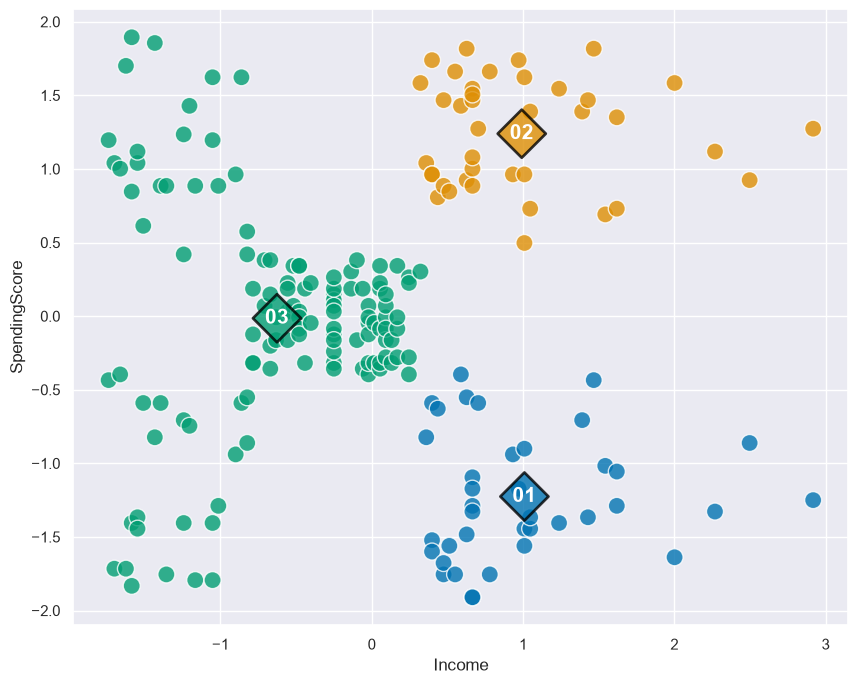

In [ ]:
# Visualização gráfica dos clusters e centroides
# confugurando o tamanho do gráfico
plt.figure(figsize=(10, 8))

# Gráfico do cluster
plot = sns.scatterplot(
                data=df_scaled,
                x='Income',
                y='SpendingScore',
                palette="colorblind",
                alpha=0.8,
                s =150,
                legend=False,
                hue=km.labels_
            )

# Gráfico do centroide
plot = sns.scatterplot(
                data=centroids,
                x='Income',
                y='SpendingScore',
                palette="colorblind",
                alpha=0.8,
                s =600,
                marker='D',
                ec='black',
                legend=False,
                hue=centroids.index
            )


# Acrescentrando nome nos centroides
for i in range(centroids.shape[0]):
    plot.text(
        x=centroids['Income'][i],
        y=centroids['SpendingScore'][i],
        s=f'0{i+1}',
        fontdict=dict(color='white', size=15),
        weight='bold',
        horizontalalignment='center',
        verticalalignment='center'
    )


** Escolhendo o Número de Clusters - Cotovelo**

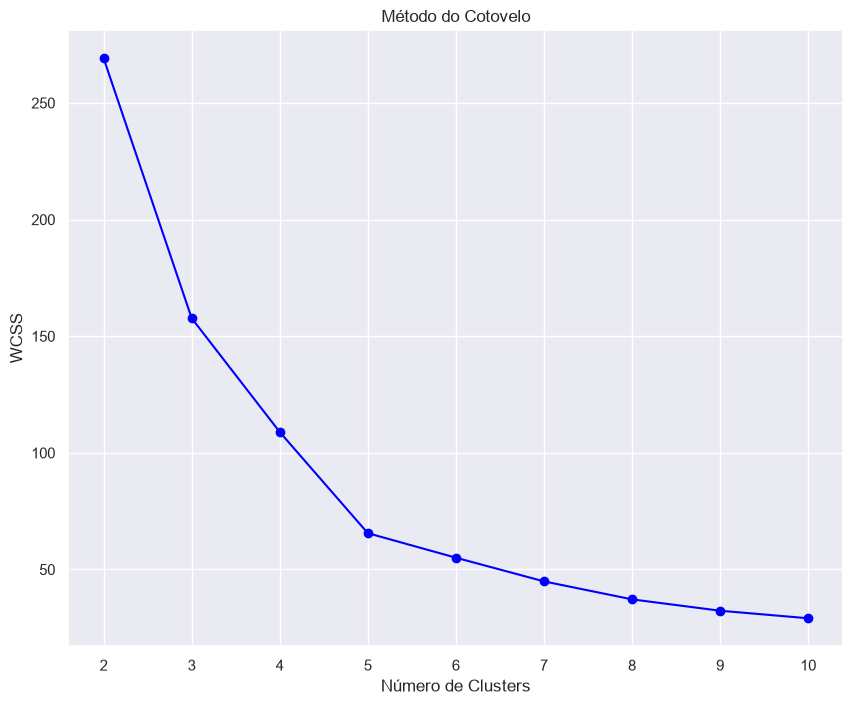

In [22]:
# Método do cotovelo para determinar o número ideal de clusters 
# - Nessa análise, o número ideal de clusters é 5, pois é o ponto onde a curva começa a se estabilizar.
wcss = []
for i in range(2, 11):
    km = KMeans(n_clusters=i, n_init=25, random_state=1234)
    km.fit(df_scaled)
    wcss.append(km.inertia_)

wcss_series = pd.Series(wcss, index=range(2, 11))    

plt.figure(figsize=(10, 8))
plt.plot(wcss_series, marker='o', color='blue')
plt.xlabel('Número de Clusters')
plt.ylabel('WCSS')
plt.title('Método do Cotovelo')
plt.show()

** Escolhendo o Número de Clusters - Método da Silhueta **

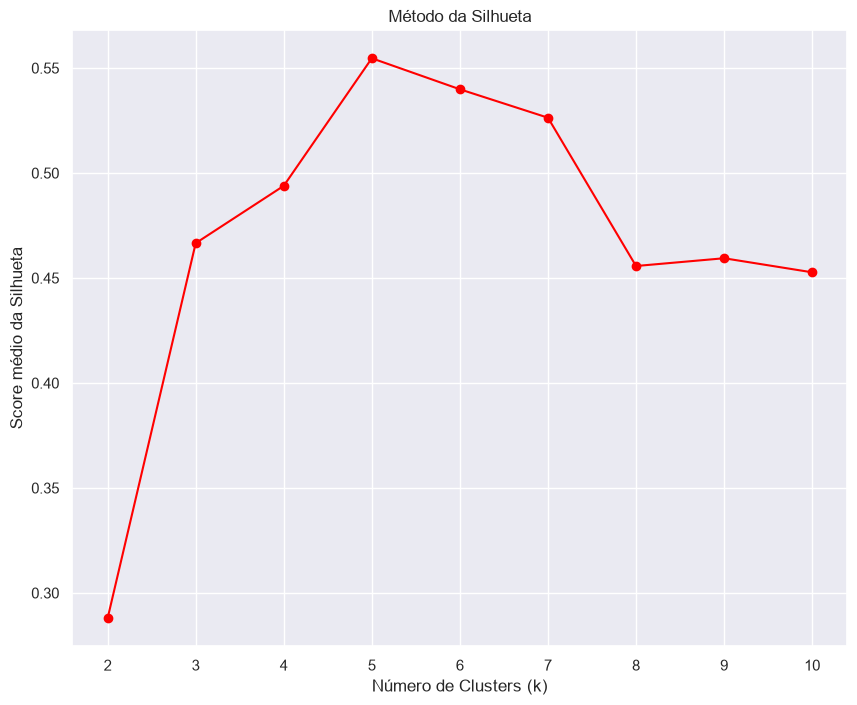

In [23]:
# Método da Silhueta para determinar o número ideal de clusters 
# - Nessa análise, o número ideal de clusters é 5, pois é o ponto máximo da curva.
silhouette = []
for i in range(2, 11):
    km = KMeans(n_clusters=i, n_init=25, random_state=1234)
    km.fit(df_scaled)
    silhouette.append(silhouette_score(df_scaled, km.labels_))

silhouette_series = pd.Series(silhouette, index=range(2, 11))

plt.figure(figsize=(10, 8))
plt.plot(silhouette_series, marker='o', color='red')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Score médio da Silhueta')
plt.title('Método da Silhueta')
plt.show()

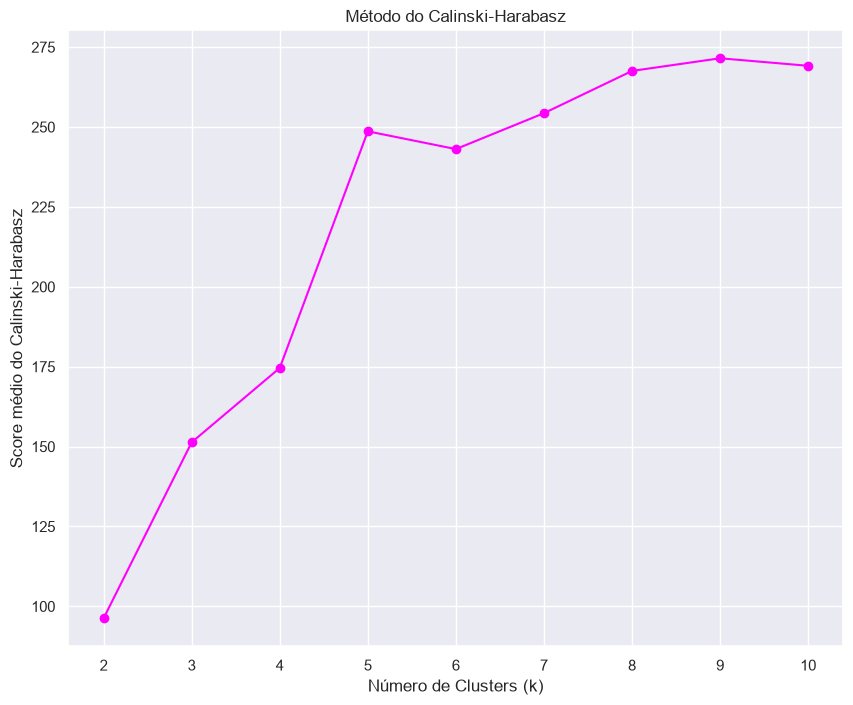

In [24]:
# Método do Calinski-Harabasz para determinar o número ideal de clusters 
# - Nessa análise, o número ideal de clusters é o primeiro ponto de inflexão da curva, que é 5 antes do valor máximo.
calinski_harabasz = []
for i in range(2, 11):
    km = KMeans(n_clusters=i, n_init=25, random_state=1234)
    km.fit(df_scaled)
    calinski_harabasz.append(calinski_harabasz_score(df_scaled, km.labels_))    

calinski_harabasz_series = pd.Series(calinski_harabasz, index=range(2, 11))

plt.figure(figsize=(10, 8))
plt.plot(calinski_harabasz_series, marker='o', color='magenta')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Score médio do Calinski-Harabasz')
plt.title('Método do Calinski-Harabasz')
plt.show()


** Analisando Clusters - de acordo com os critérios - considerando agora 5 clusters **

In [25]:
km5 = KMeans(n_clusters=5, n_init=25, random_state=1234)
km5.fit(df_scaled) 

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",25
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",1234
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 2)","[[-

In [26]:
df_scaled.head(1)

,Income,SpendingScore
0,-1.738999,-0.434801


In [27]:
centroids5 = pd.DataFrame(km5.cluster_centers_, columns=['Income', 'SpendingScore'])

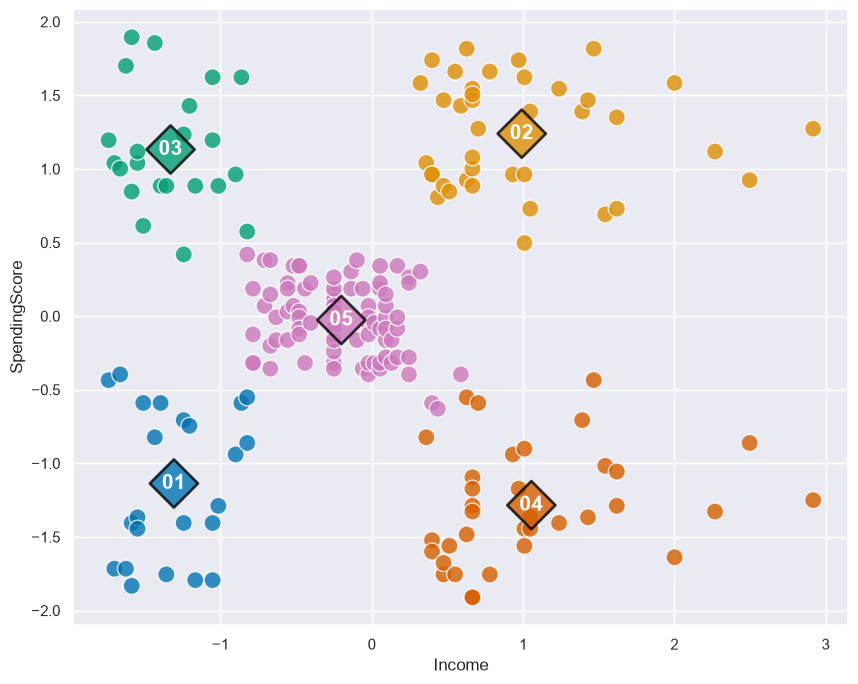

In [28]:
# confugurando o tamanho do gráfico
plt.figure(figsize=(10, 8))

# Gráfico do cluster
plot = sns.scatterplot(
                data=df_scaled,
                x='Income',
                y='SpendingScore',
                palette="colorblind",
                alpha=0.8,
                s =150,
                legend=False,
                hue=km5.labels_
            )

# Gráfico do centroide
plot = sns.scatterplot(
                data=centroids5,
                x='Income',
                y='SpendingScore',
                palette="colorblind",
                alpha=0.8,
                s =600,
                marker='D',
                ec='black',
                legend=False,
                hue=centroids5.index
            )


# Acrescentrando nome nos centroides
for i in range(centroids5.shape[0]):
    plot.text(
        x=centroids5['Income'][i],
        y=centroids5['SpendingScore'][i],
        s=f'0{i+1}',
        fontdict=dict(color='white', size=15),
        weight='bold',
        horizontalalignment='center',
        verticalalignment='center'
    )


In [29]:
# Acrescentando a coluna de cluster no dataframe original
df['Cluster'] = km5.labels_.tolist()
df.head(10)

,CustomerID,Gender,Age,Income,SpendingScore,Cluster
0,1,Male,19,15000,39,0
1,2,Male,21,15000,81,2
2,3,Female,20,16000,6,0
3,4,Female,23,16000,77,2
4,5,Female,31,17000,40,0
5,6,Female,22,17000,76,2
6,7,Female,35,18000,6,0
7,8,Female,23,18000,94,2
8,9,Male,64,19000,3,0
9,10,Female,30,19000,72,2


In [30]:
# Criando dummies para a coluna de cluster genero
df = pd.get_dummies(df, columns=['Gender'])
df.head(10)

,CustomerID,Age,Income,SpendingScore,Cluster,Gender_Female,Gender_Male
0,1,19,15000,39,0,False,True
1,2,21,15000,81,2,False,True
2,3,20,16000,6,0,True,False
3,4,23,16000,77,2,True,False
4,5,31,17000,40,0,True,False
5,6,22,17000,76,2,True,False
6,7,35,18000,6,0,True,False
7,8,23,18000,94,2,True,False
8,9,64,19000,3,0,False,True
9,10,30,19000,72,2,True,False


In [31]:
# Estatísticas descritivas dos clusters
df.agg({'Gender_Female': 'mean',
         'Gender_Male': 'mean',
         'Age': 'mean', 
         'Income': 'mean', 
         'SpendingScore': 'mean'}).round(2)

Gender_Female        0.56
Gender_Male          0.44
Age                 38.85
Income           60560.00
SpendingScore       50.20
dtype: float64

In [32]:
df.groupby('Cluster').agg({'Gender_Female': 'mean',
                           'Gender_Male': 'mean',
                           'Age': 'median' ,
                           'Income': 'median',
                           'SpendingScore': 'median'}).round(2)

,Gender_Female,Gender_Male,Age,Income,SpendingScore
Cluster,,,,,
0,0.61,0.39,46.0,25000.0,17.0
1,0.54,0.46,32.0,79000.0,83.0
2,0.59,0.41,23.5,24500.0,77.0
3,0.46,0.54,42.0,85000.0,16.0
4,0.59,0.41,46.0,54000.0,50.0
